In [ ]:

from google.colab import files

uploaded = files.upload()

zip_files = [
    name for name in uploaded
    if name.lower().endswith(".zip")
]

print("ZIP files uploaded:", zip_files)


Saving Bangladesh Multi-Institution Oral Cancer Dataset (.zip to Bangladesh Multi-Institution Oral Cancer Dataset (.zip
ZIP files uploaded: ['Bangladesh Multi-Institution Oral Cancer Dataset (.zip']


In [ ]:

import zipfile
from pathlib import Path

if not zip_files:
    raise ValueError("Please upload the dataset ZIP file first.")

zip_path = zip_files[0]
data_dir = Path("/content/oral_dataset")
data_dir.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as z:
    z.extractall(data_dir)

print("Extraction complete!")
print("\nTop-level contents:")

for item in sorted(data_dir.iterdir()):
    print(("Folder: " if item.is_dir() else "File: ") + item.name)


Extraction complete!

Top-level contents:
Folder: Bangladesh Multi-Institution Oral Cancer Dataset (


In [ ]:

from pathlib import Path

image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

images = [
    p for p in data_dir.rglob("*")
    if p.is_file() and p.suffix.lower() in image_extensions
]

print("Total image files found:", len(images))
print("\nExample file paths:")

for p in images[:20]:
    print(p.relative_to(data_dir))


Total image files found: 0

Example file paths:


In [ ]:

from pathlib import Path
from collections import Counter

root = Path("/content/oral_dataset")

print("Does extraction folder exist?", root.exists())
print("\nFiles and folders (first 80):")

items = list(root.rglob("*"))
for item in items[:80]:
    kind = "DIR " if item.is_dir() else "FILE"
    print(f"{kind} | {item.relative_to(root)}")

print("\nFile extension counts:")
counts = Counter(
    p.suffix.lower() or "[no extension]"
    for p in items if p.is_file()
)
print(counts)

print("\nNested ZIP files:")
for p in root.rglob("*.zip"):
    print(p)


Does extraction folder exist? True

Files and folders (first 80):
DIR  | Bangladesh Multi-Institution Oral Cancer Dataset (
FILE | Bangladesh Multi-Institution Oral Cancer Dataset (/Dataset 1.zip

File extension counts:
Counter({'.zip': 1})

Nested ZIP files:
/content/oral_dataset/Bangladesh Multi-Institution Oral Cancer Dataset (/Dataset 1.zip


In [ ]:

import zipfile
from pathlib import Path

nested_zip = Path(
    "/content/oral_dataset/"
    "Bangladesh Multi-Institution Oral Cancer Dataset ("
    "/Dataset 1.zip"
)

extract_dir = Path("/content/oral_dataset/extracted")
extract_dir.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(nested_zip, "r") as z:
    print("Files inside inner ZIP:", len(z.namelist()))
    print("First 30 entries:")
    for name in z.namelist()[:30]:
        print(name)

    z.extractall(extract_dir)

print("\nExtraction complete!")


Files inside inner ZIP: 813
First 30 entries:
Dataset/
Dataset/Mitford Hospital/
Dataset/Mitford Hospital/Cancer/
Dataset/Mitford Hospital/Cancer/cancer_1.jpg
Dataset/Mitford Hospital/Cancer/cancer_10.jpg
Dataset/Mitford Hospital/Cancer/cancer_11.jpg
Dataset/Mitford Hospital/Cancer/cancer_12.jpg
Dataset/Mitford Hospital/Cancer/cancer_13.jpg
Dataset/Mitford Hospital/Cancer/cancer_14.jpg
Dataset/Mitford Hospital/Cancer/cancer_15.jpg
Dataset/Mitford Hospital/Cancer/cancer_16.jpg
Dataset/Mitford Hospital/Cancer/cancer_17.jpg
Dataset/Mitford Hospital/Cancer/cancer_18.jpg
Dataset/Mitford Hospital/Cancer/cancer_19.jpg
Dataset/Mitford Hospital/Cancer/cancer_2.jpg
Dataset/Mitford Hospital/Cancer/cancer_20.jpg
Dataset/Mitford Hospital/Cancer/cancer_21.jpg
Dataset/Mitford Hospital/Cancer/cancer_22.jpg
Dataset/Mitford Hospital/Cancer/cancer_23.jpg
Dataset/Mitford Hospital/Cancer/cancer_24.jpg
Dataset/Mitford Hospital/Cancer/cancer_25.jpg
Dataset/Mitford Hospital/Cancer/cancer_26.jpg
Dataset/Mitfor

In [ ]:

from pathlib import Path
from collections import Counter

root = Path("/content/oral_dataset/extracted")

extensions = {
    ".jpg", ".jpeg", ".png", ".bmp",
    ".webp", ".tif", ".tiff"
}

images = [
    p for p in root.rglob("*")
    if p.is_file() and p.suffix.lower() in extensions
]

print("Total images found:", len(images))
print("File extensions:", Counter(p.suffix.lower() for p in images))

print("\nExample paths:")
for p in images[:20]:
    print(p.relative_to(root))


Total images found: 800
File extensions: Counter({'.jpg': 800})

Example paths:
Dataset/Mitford Hospital/Cancer/cancer_24.jpg
Dataset/Mitford Hospital/Cancer/cancer_53.jpg
Dataset/Mitford Hospital/Cancer/cancer_19.jpg
Dataset/Mitford Hospital/Cancer/cancer_22.jpg
Dataset/Mitford Hospital/Cancer/cancer_54.jpg
Dataset/Mitford Hospital/Cancer/cancer_68.jpg
Dataset/Mitford Hospital/Cancer/cancer_5.jpg
Dataset/Mitford Hospital/Cancer/cancer_13.jpg
Dataset/Mitford Hospital/Cancer/cancer_50.jpg
Dataset/Mitford Hospital/Cancer/cancer_8.jpg
Dataset/Mitford Hospital/Cancer/cancer_34.jpg
Dataset/Mitford Hospital/Cancer/cancer_41.jpg
Dataset/Mitford Hospital/Cancer/cancer_29.jpg
Dataset/Mitford Hospital/Cancer/cancer_56.jpg
Dataset/Mitford Hospital/Cancer/cancer_70.jpg
Dataset/Mitford Hospital/Cancer/cancer_27.jpg
Dataset/Mitford Hospital/Cancer/cancer_15.jpg
Dataset/Mitford Hospital/Cancer/cancer_10.jpg
Dataset/Mitford Hospital/Cancer/cancer_1.jpg
Dataset/Mitford Hospital/Cancer/cancer_23.jpg


In [ ]:

from pathlib import Path
from collections import Counter

root = Path("/content/oral_dataset/extracted/Dataset")

image_exts = {".jpg", ".jpeg", ".png", ".webp", ".bmp"}

# Count images by their immediate class folder
class_counts = Counter()
hospital_counts = Counter()

for p in root.rglob("*"):
    if p.is_file() and p.suffix.lower() in image_exts:
        parts = p.relative_to(root).parts

        if len(parts) >= 3:
            hospital = parts[0]
            label = parts[1]
            class_counts[label] += 1
            hospital_counts[(hospital, label)] += 1

print("TOTAL IMAGES BY CLASS")
for label, count in sorted(class_counts.items()):
    print(f"{label}: {count}")

print("\nIMAGES BY HOSPITAL AND CLASS")
for (hospital, label), count in sorted(hospital_counts.items()):
    print(f"{hospital} | {label}: {count}")

print("\nTOP-LEVEL FOLDERS")
for p in sorted(root.iterdir()):
    if p.is_dir():
        print(p.name, "->", [x.name for x in p.iterdir() if x.is_dir()])


TOTAL IMAGES BY CLASS
Cancer: 330
Non_Cancer: 470

IMAGES BY HOSPITAL AND CLASS
Mitford Hospital | Cancer: 71
Mitford Hospital | Non_Cancer: 101
Reshmi Dental | Cancer: 39
Reshmi Dental | Non_Cancer: 55
Shuvro Dental | Cancer: 155
Shuvro Dental | Non_Cancer: 221
Uposhomo Dental | Cancer: 65
Uposhomo Dental | Non_Cancer: 93

TOP-LEVEL FOLDERS
Mitford Hospital -> ['Cancer', 'Non_Cancer']
Reshmi Dental -> ['Cancer', 'Non_Cancer']
Shuvro Dental -> ['Cancer', 'Non_Cancer']
Uposhomo Dental -> ['Cancer', 'Non_Cancer']


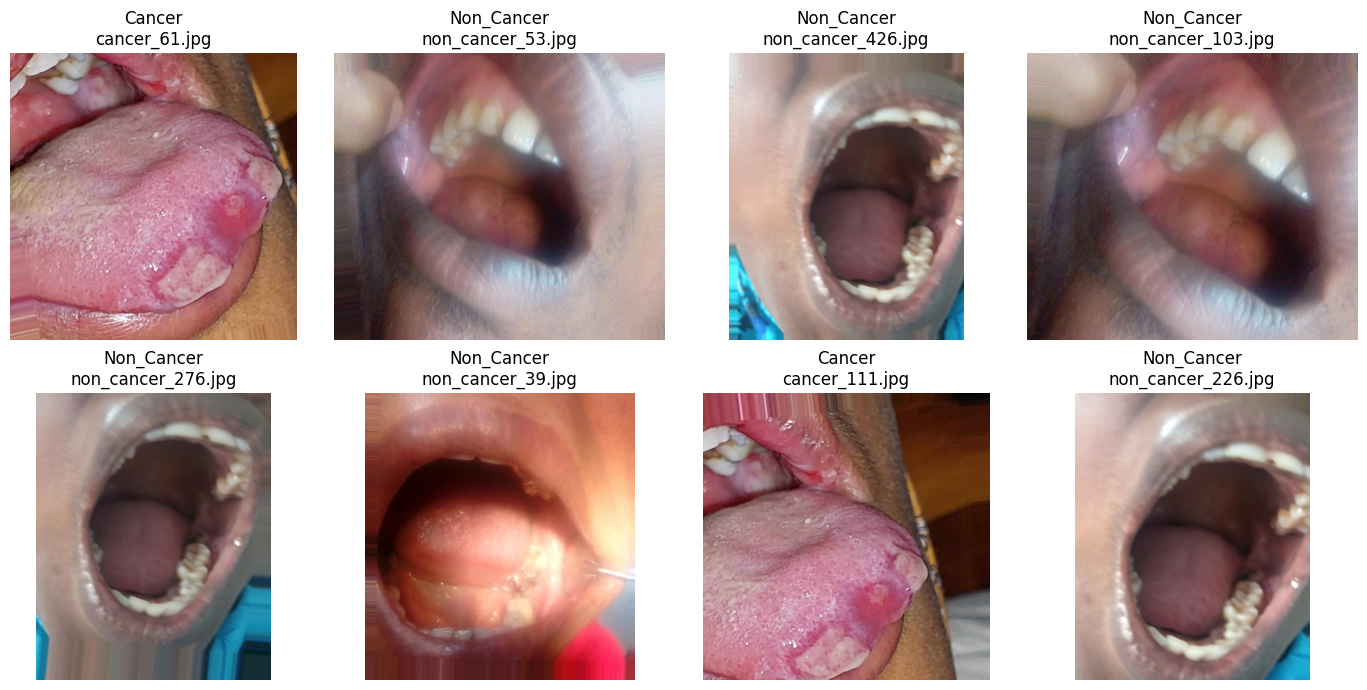

In [ ]:

from PIL import Image
import matplotlib.pyplot as plt
import random

all_images = [
    p for p in root.rglob("*")
    if p.is_file() and p.suffix.lower() in image_exts
]

sample_images = random.sample(all_images, min(8, len(all_images)))

fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for ax, path in zip(axes.flat, sample_images):
    ax.imshow(Image.open(path).convert("RGB"))
    ax.set_title(f"{path.parent.name}\n{path.name}")
    ax.axis("off")

for ax in axes.flat[len(sample_images):]:
    ax.axis("off")

plt.tight_layout()
plt.show()


In [ ]:

from pathlib import Path
from PIL import Image
from collections import defaultdict
import hashlib

root = Path("/content/oral_dataset/extracted/Dataset")
extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

hash_groups = defaultdict(list)
bad_files = []

for p in root.rglob("*"):
    if not p.is_file() or p.suffix.lower() not in extensions:
        continue
    try:
        # Hash decoded pixels so identical photos with different filenames
        # or JPEG metadata can still be identified when pixel data matches.
        with Image.open(p) as im:
            im = im.convert("RGB")
            digest = hashlib.sha256(im.tobytes()).hexdigest()
        hash_groups[digest].append(p)
    except Exception:
        bad_files.append(str(p))

duplicate_groups = [paths for paths in hash_groups.values() if len(paths) > 1]

print("Unique decoded images:", len(hash_groups))
print("Exact duplicate groups:", len(duplicate_groups))
print("Files in duplicate groups:",
      sum(len(g) for g in duplicate_groups))
print("Unreadable images:", len(bad_files))

for group in duplicate_groups[:15]:
    print("\nDuplicate group:")
    for p in group:
        print(" ", p.relative_to(root))


Unique decoded images: 800
Exact duplicate groups: 0
Files in duplicate groups: 0
Unreadable images: 0


Total images: 800

Class counts:
 label
Non_Cancer    470
Cancer        330
Name: count, dtype: int64

Hospital counts:
 hospital          label     
Mitford Hospital  Cancer         71
                  Non_Cancer    101
Reshmi Dental     Cancer         39
                  Non_Cancer     55
Shuvro Dental     Cancer        155
                  Non_Cancer    221
Uposhomo Dental   Cancer         65
                  Non_Cancer     93
dtype: int64

Train: 339 
Validation: 85 
Held-out hospital test: 376

Test class counts:
 label
Non_Cancer    221
Cancer        155
Name: count, dtype: int64
Found 339 validated image filenames belonging to 2 classes.
Found 85 validated image filenames belonging to 2 classes.
Found 376 validated image filenames belonging to 2 classes.
Label mapping: {'Cancer': 0, 'Non_Cancer': 1}
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Class weights: {0: 1.2107142857142856, 1: 0.8517587939698492}
Epoch 1/15
22/22 ━━━━━━━━━━━━━━━━━━━━ 38s 1s/step - accuracy: 0.536

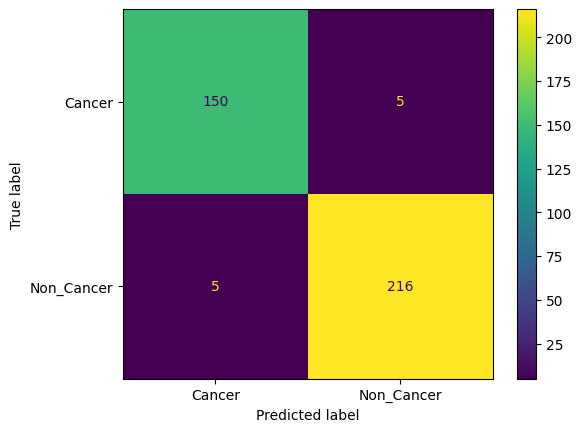

Cancer sensitivity: 0.968
Cancer specificity: 0.977


AttributeError: 'bool' object has no attribute 'astype'

In [ ]:

import os
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score
)
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from tensorflow.keras import layers, models

# 1. Find images and their labels from the folder structure
root = Path("/content/oral_dataset/extracted/Dataset")
extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

records = []
for p in root.rglob("*"):
    if p.is_file() and p.suffix.lower() in extensions:
        parts = p.relative_to(root).parts
        if len(parts) >= 3:
            hospital, label = parts[0], parts[1]
            if label in {"Cancer", "Non_Cancer"}:
                records.append({
                    "filepath": str(p),
                    "hospital": hospital,
                    "label": label
                })

df = pd.DataFrame(records)
print("Total images:", len(df))
print("\nClass counts:\n", df["label"].value_counts())
print("\nHospital counts:\n", df.groupby(["hospital", "label"]).size())

# 2. Keep one whole hospital out of training
test_hospital = "Shuvro Dental"
test_df = df[df["hospital"] == test_hospital].copy()
development_df = df[df["hospital"] != test_hospital].copy()

if test_df.empty or development_df.empty:
    raise ValueError("Hospital folder names don't match. Check the printed hospital counts.")

# Split remaining hospitals into training and validation images.
# This is image-level validation, not patient-level validation.
train_df, val_df = train_test_split(
    development_df,
    test_size=0.20,
    random_state=42,
    stratify=development_df["label"]
)

print("\nTrain:", len(train_df), "\nValidation:", len(val_df),
      "\nHeld-out hospital test:", len(test_df))
print("\nTest class counts:\n", test_df["label"].value_counts())

# 3. Load images; augment training images only
IMG_SIZE = (224, 224)
BATCH_SIZE = 16
SEED = 42

train_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    rotation_range=12,
    width_shift_range=0.08,
    height_shift_range=0.08,
    zoom_range=0.10,
    horizontal_flip=True
)
eval_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input
)

train_gen = train_datagen.flow_from_dataframe(
    train_df,
    x_col="filepath",
    y_col="label",
    classes=["Cancer", "Non_Cancer"],
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="binary",
    shuffle=True,
    seed=SEED
)
val_gen = eval_datagen.flow_from_dataframe(
    val_df,
    x_col="filepath",
    y_col="label",
    classes=["Cancer", "Non_Cancer"],
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="binary",
    shuffle=False
)
test_gen = eval_datagen.flow_from_dataframe(
    test_df,
    x_col="filepath",
    y_col="label",
    classes=["Cancer", "Non_Cancer"],
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="binary",
    shuffle=False
)

print("Label mapping:", train_gen.class_indices)
# With this mapping, Cancer=0 and Non_Cancer=1.
# The output probability is therefore P(Non_Cancer).

# 4. Build the transfer-learning model
base = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)
base.trainable = False

inputs = layers.Input(shape=(224, 224, 3))
x = base(inputs, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.30)(x)
outputs = layers.Dense(1, activation="sigmoid")(x)
model = models.Model(inputs, outputs)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="binary_crossentropy",
    metrics=[
        tf.keras.metrics.BinaryAccuracy(name="accuracy"),
        tf.keras.metrics.AUC(name="auc")
    ]
)

# 5. Compensate for class imbalance in training data
classes = np.array([0, 1])
weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=train_gen.classes
)
class_weights = {int(c): float(w) for c, w in zip(classes, weights)}
print("Class weights:", class_weights)

callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=4, restore_best_weights=True
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss", factor=0.3, patience=2, min_lr=1e-6
    )
]

history = model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=15,
    class_weight=class_weights,
    callbacks=callbacks
)

# 6. Evaluate once on the held-out hospital
test_gen.reset()
p_non_cancer = model.predict(test_gen).ravel()
y_true = test_gen.classes

# Threshold 0.5 is a starting point, not a medically validated threshold.
y_pred = (p_non_cancer >= 0.5).astype(int)

print("\nClassification report:")
print(classification_report(
    y_true, y_pred,
    labels=[0, 1],
    target_names=["Cancer", "Non_Cancer"],
    zero_division=0
))

cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Cancer", "Non_Cancer"]
).plot()
plt.show()

# Cancer is class 0, so its sensitivity is recall for class 0.
tn_for_cancer, fp_for_cancer, fn_for_cancer, tp_for_cancer = (
    cm[1, 1], cm[1, 0], cm[0, 1], cm[0, 0]
)
cancer_sensitivity = tp_for_cancer / max(
    tp_for_cancer + fn_for_cancer, 1
)
cancer_specificity = tn_for_cancer / max(
    tn_for_cancer + fp_for_cancer, 1
)

print(f"Cancer sensitivity: {cancer_sensitivity:.3f}")
print(f"Cancer specificity: {cancer_specificity:.3f}")

try:
    print("ROC AUC:",
          roc_auc_score((y_true == 1).astype(int), p_non_cancer))
except ValueError:
    print("ROC AUC unavailable: test set contains only one class.")

# 7. Save model
model.save("/content/oncosniff_mobilenetv2.keras")
print("Saved model: /content/oncosniff_mobilenetv2.keras")


In [ ]:

import numpy as np
from sklearn.metrics import roc_auc_score

y_true_np = np.asarray(y_true).astype(int).ravel()
p_non_cancer_np = np.asarray(p_non_cancer).ravel()

# Label mapping: Cancer=0, Non_Cancer=1
# Convert probability to probability of Cancer.
p_cancer_np = 1.0 - p_non_cancer_np

roc_auc = roc_auc_score(
    (y_true_np == 0).astype(int),
    p_cancer_np
)

print(f"Cancer ROC-AUC: {roc_auc:.4f}")

# Save the trained model
model.save("/content/oncosniff_mobilenetv2.keras")
print("Model saved successfully!")


Cancer ROC-AUC: 0.9975
Model saved successfully!


In [ ]:
from google.colab import files

files.download('/content/oncosniff_mobilenetv2.keras')